# 1. Correlation between variables
In this first part, the goal is to evaluate the correlation between the available variables and the HAB value to take some initial conclusions before starting on the models.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import auxilary functions developed by us to better read the data
from aux import read_table, month_sine

# Configuration of the plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 8)



# Uploading the data
df = read_table("../../data/classification_task1_train.csv")

# Applying the continuous transformation
df_corr = month_sine(df)

# Convert 'Season' and 'spatial_cluster' into numerical binary columns with One-Hot Encoding 
# in order to see the correlation between month and HAB
df_corr = pd.get_dummies(df_corr, columns=["Season", "spatial_cluster"], dtype=float)

# Removing columns that make no sence for the correlation part
cols_to_drop = ["Date", "Day", "Year"]
df_corr = df_corr.drop(columns=[c for c in cols_to_drop if c in df_corr.columns])

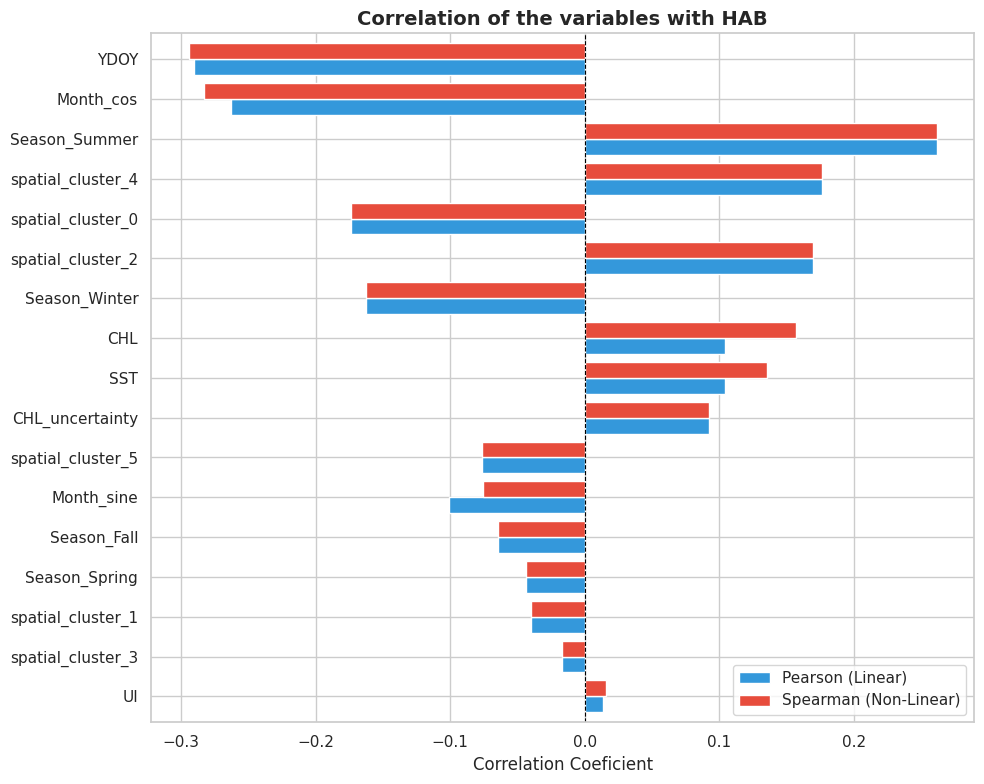

In [5]:
# Calculating correlations with the target variable HAB 
# Pearson: Linear correlation - if the relation is given by a line (sensible to outliers)
# Spearman: Non-Linear correlation - sees if one variable grows the other also grows, but not necessarely in a line

pearson_corr = df_corr.corr(method="pearson")["HAB"].drop("HAB")
spearman_corr = df_corr.corr(method="spearman")["HAB"].drop("HAB")

# Bring the results into a DataFrame and sorting it by absolute value of Spearman
corr_summary = pd.DataFrame({
    "Pearson (Linear)": pearson_corr,
    "Spearman (Non-Linear)": spearman_corr
})
corr_summary = corr_summary.reindex(
    corr_summary["Spearman (Non-Linear)"].abs().sort_values(ascending=True).index
)

# Plots with horizontal bars
ax = corr_summary.plot(kind="barh", figsize=(10, 8), color=["#3498db", "#e74c3c"], width=0.8)
plt.title("Correlation of the variables with HAB", fontsize=14, fontweight="bold")
plt.xlabel("Correlation Coeficient")
plt.axvline(0, color="black", linewidth=0.8, linestyle="--")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Main conclusions:
- Time variable susch as YDOY, Month:cos, Season Summer etc show a strong correlation with HAB, showing the seasonality of this phenomenon.
- UI alone has a very low correlation
- CHL, SST and CHL_uncertainty show a stronger non-linear correlation than linear, giving a hint that the relationship might not be linear with HAB

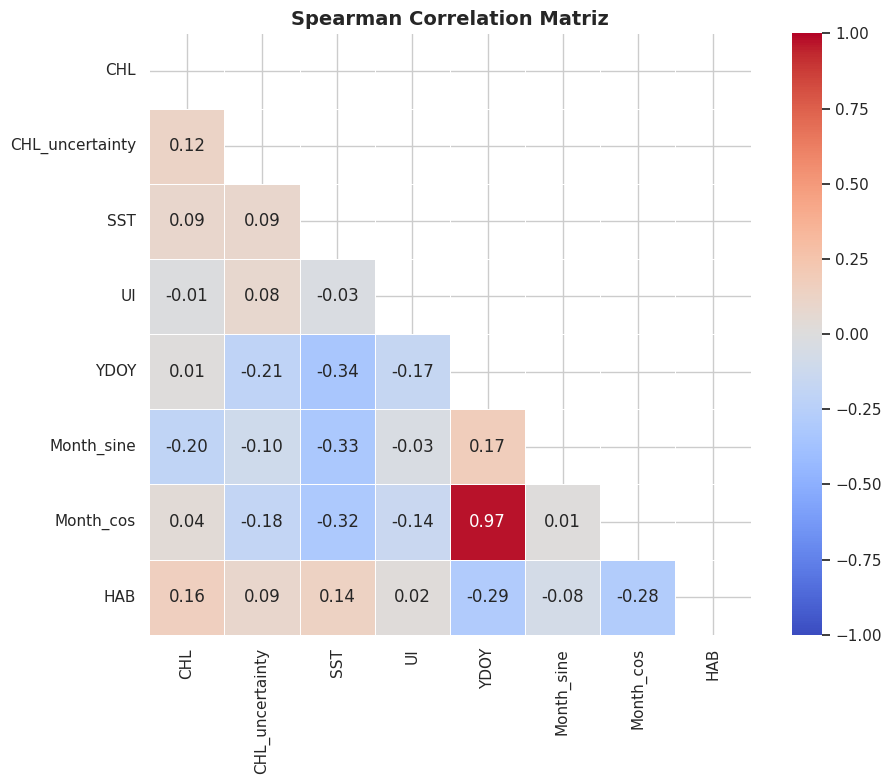

In [6]:
# Selecting solely the main variables in order for the plot to not get confusing
main_cols = [
    "CHL", "CHL_uncertainty", "SST", "UI", 
    "YDOY", "Month_sine", "Month_cos", "HAB"
]
corr_matrix = df_corr[main_cols].corr(method="spearman")

# Criar máscara para esconder o triângulo superior repetido
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, vmax=1, 
    center=0,
    square=True, 
    linewidths=0.5
)
plt.title("Spearman Correlation Matriz", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Main Conclusions:
- Strong correlation between Month_cos and YDOY (we should inly use one of them)
- SST varies strongly with YODY and Month_sine, which makes sense since tmeprature varies around the year
- The rest of the variables hava  low correlation between them, wich means they may bring different information among them

/tmp/ipykernel_12863/361833495.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_12863/361833495.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_12863/361833495.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_12863/361833495.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_12863/361833495.py:7: FutureWarning: 

Passin

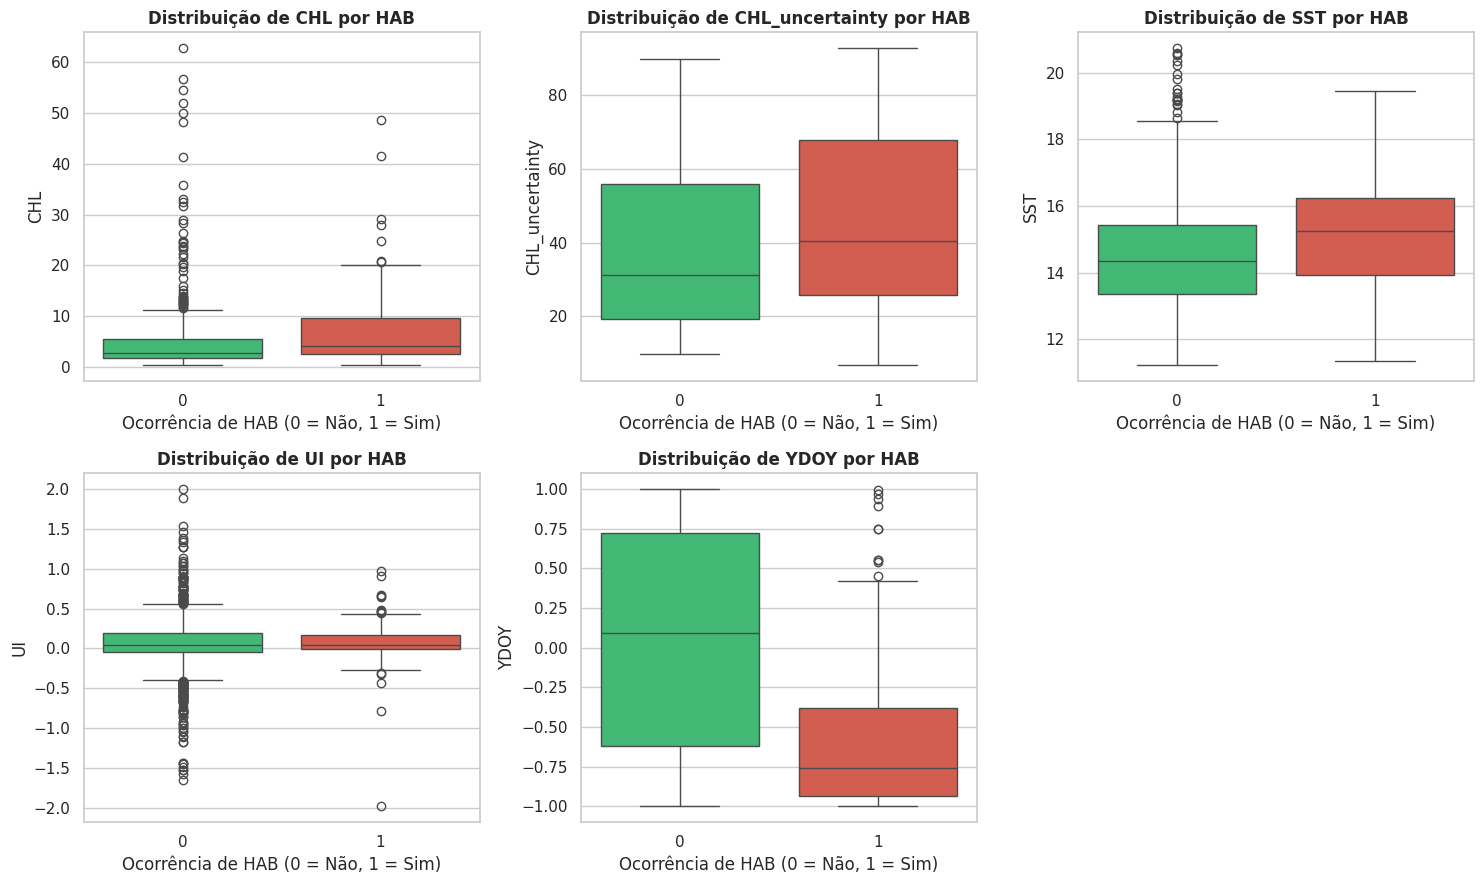

In [7]:
physical_vars = ["CHL", "CHL_uncertainty", "SST", "UI", "YDOY"]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(physical_vars):
    sns.boxplot(
        data=df, 
        x="HAB", 
        y=col, 
        ax=axes[i], 
        palette=["#2ecc71", "#e74c3c"],
        showfliers=True # True - shows extreme outliers, False - does not show them
    )
    axes[i].set_title(f"Distribuição de {col} por HAB", fontweight="bold")
    axes[i].set_xlabel("Ocorrência de HAB (0 = Não, 1 = Sim)")

# Esconder o 6º subplot vazio
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

Main Conclusions:
- YDOY shows a dramatic separations, meaning that HAB are highly concentrated in certain times of the year
- Higher SST favours HAB
- CHL has a lot of outliers, maybe log will help
- UI is very similar for HAB or no HAB, meaning that it may not be very usefull, unless some more developed algorithm can take information from it

/tmp/ipykernel_12863/689277136.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_hab.index, y=cluster_hab.values, ax=axes[0], palette="viridis")
/tmp/ipykernel_12863/689277136.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=season_hab.index, y=season_hab.values, ax=axes[1], palette="magma")


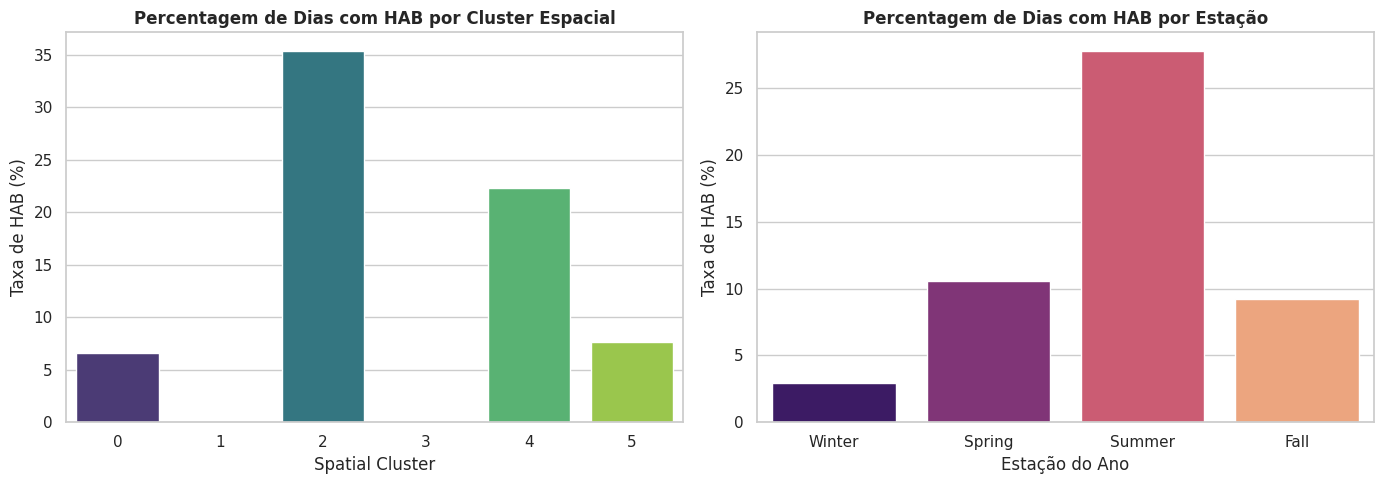

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Taxa de HAB por Cluster Espacial
cluster_hab = df.groupby("spatial_cluster")["HAB"].mean() * 100
sns.barplot(x=cluster_hab.index, y=cluster_hab.values, ax=axes[0], palette="viridis")
axes[0].set_title("Percentagem de Dias com HAB por Cluster Espacial", fontweight="bold")
axes[0].set_ylabel("Taxa de HAB (%)")
axes[0].set_xlabel("Spatial Cluster")

# Taxa de HAB por Estação do Ano
season_order = ["Winter", "Spring", "Summer", "Fall"]
season_hab = df.groupby("Season")["HAB"].mean().reindex(season_order) * 100
sns.barplot(x=season_hab.index, y=season_hab.values, ax=axes[1], palette="magma")
axes[1].set_title("Percentagem de Dias com HAB por Estação", fontweight="bold")
axes[1].set_ylabel("Taxa de HAB (%)")
axes[1].set_xlabel("Estação do Ano")

plt.tight_layout()
plt.show()

Main Conclusions:
- HAB happens mostly in clusters 2 and 4, and never happen in 1 and 3. this variable is extreely important to help discriminate
- HAB is highly correlated with the season of the year, as already seen above

Percentagem de dias em que CHL e CHL_uncertainty coincidem nos NaNs: 100.00%


/tmp/ipykernel_12863/393689385.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_season.index, y=missing_season.values, ax=axes[0], palette="Blues_d")
/tmp/ipykernel_12863/393689385.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_cluster.index, y=missing_cluster.values, ax=axes[1], palette="Greens_d")


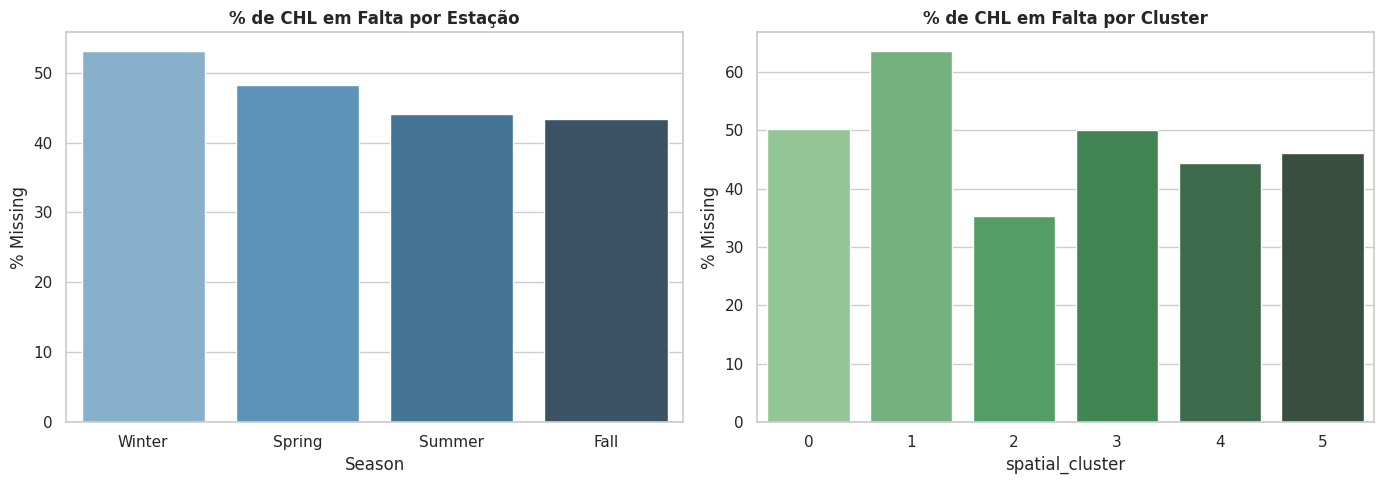


Taxa média de HAB (%) quando CHL está presente (0) vs ausente (1):
is_chl_missing
0    14.742451
1    11.000000
Name: HAB, dtype: float64


In [9]:
# 1. Verificar se CHL e CHL_uncertainty faltam exatamente nos mesmos dias
mesmos_nans = (df["CHL"].isna() == df["CHL_uncertainty"].isna()).mean() * 100
print(f"Percentagem de dias em que CHL e CHL_uncertainty coincidem nos NaNs: {mesmos_nans:.2f}%")

# 2. Taxa de valores ausentes por Estação do Ano e por Cluster
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

missing_season = df.groupby("Season")["CHL"].apply(lambda x: x.isna().mean() * 100).reindex(["Winter", "Spring", "Summer", "Fall"])
sns.barplot(x=missing_season.index, y=missing_season.values, ax=axes[0], palette="Blues_d")
axes[0].set_title("% de CHL em Falta por Estação", fontweight="bold")
axes[0].set_ylabel("% Missing")

missing_cluster = df.groupby("spatial_cluster")["CHL"].apply(lambda x: x.isna().mean() * 100)
sns.barplot(x=missing_cluster.index, y=missing_cluster.values, ax=axes[1], palette="Greens_d")
axes[1].set_title("% de CHL em Falta por Cluster", fontweight="bold")
axes[1].set_ylabel("% Missing")

plt.tight_layout()
plt.show()

# 3. A taxa de HAB muda quando a CHL está ausente vs presente?
df["is_chl_missing"] = df["CHL"].isna().astype(int)
print("\nTaxa média de HAB (%) quando CHL está presente (0) vs ausente (1):")
print(df.groupby("is_chl_missing")["HAB"].mean() * 100)

Main Conclusions:
-  There seems that no correlations exists between the missing CHL values and Season or spatial cluster, inting that it may be aleatory.

/tmp/ipykernel_12863/3311228001.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_year.index, y=missing_year.values, ax=axes[0], palette="Purples_d")
/tmp/ipykernel_12863/3311228001.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["CHL Presente (0)", "CHL Ausente (1)"], y=hab_by_missing.values, ax=axes[1], palette=["#2ecc71", "#e67e22"])


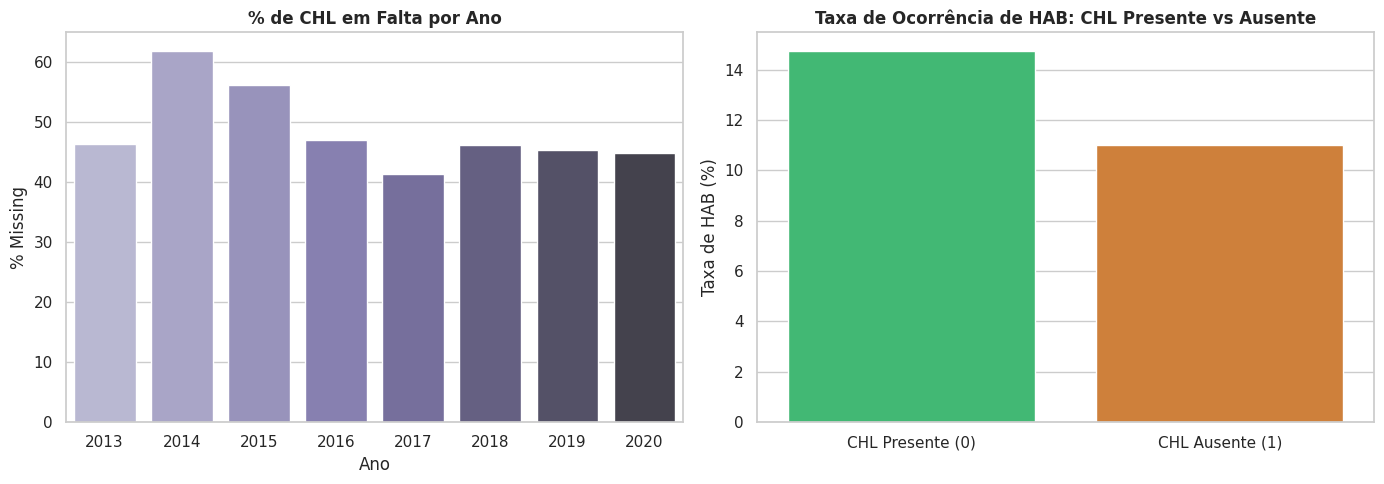

      total_amostras  pct_missing_chl  taxa_hab_pct
Year                                               
2013             112            46.43          8.93
2014              84            61.90          0.00
2015              57            56.14         47.37
2016             153            47.06         12.42
2017             174            41.38          0.00
2018             162            46.30         13.58
2019             163            45.40         17.79
2020             158            44.94         19.62


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. % de CHL em falta por Ano
missing_year = df.groupby("Year")["CHL"].apply(lambda x: x.isna().mean() * 100)
sns.barplot(x=missing_year.index, y=missing_year.values, ax=axes[0], palette="Purples_d")
axes[0].set_title("% de CHL em Falta por Ano", fontweight="bold")
axes[0].set_ylabel("% Missing")
axes[0].set_xlabel("Ano")

# 2. Taxa de HAB (%) quando CHL está presente (0) vs ausente (1)
df["is_chl_missing"] = df["CHL"].isna().astype(int)
hab_by_missing = df.groupby("is_chl_missing")["HAB"].mean() * 100
sns.barplot(x=["CHL Presente (0)", "CHL Ausente (1)"], y=hab_by_missing.values, ax=axes[1], palette=["#2ecc71", "#e67e22"])
axes[1].set_title("Taxa de Ocorrência de HAB: CHL Presente vs Ausente", fontweight="bold")
axes[1].set_ylabel("Taxa de HAB (%)")

plt.tight_layout()
plt.show()

# Imprimir a tabela exata de contagem de amostras e % de NaNs por ano
summary_year = df.groupby("Year").agg(
    total_amostras=("HAB", "count"),
    pct_missing_chl=("CHL", lambda x: round(x.isna().mean() * 100, 2)),
    taxa_hab_pct=("HAB", lambda x: round(x.mean() * 100, 2))
)
print(summary_year)

Main Conclsions:
- There also seems to exist no correlations between missing CHL values and year, as well as between the presence of CHL values and an HAB phenomenon. 
- However, years 2014 and 2017 have no HAB phenomena, so calculating the AUC metric for this years alone would be impossible.

In [4]:
from __future__ import annotations
import pickle
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import argparse
from pathlib import Path
import gc
import pandas as pd
from scipy.stats import zscore

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score
from aux import read_table, log_experiment, month_sine

df = read_table("../../data/classification_task1_train.csv")

for c in range(6):
    df[f"cluster_{c}"] = (df["spatial_cluster"] == c).astype(float)

for s in ["Winter", "Spring", "Summer", "Fall"]:
    df[f"season_{s}"] = (df["Season"] == s).astype(float)

doy = df["Date"].dt.dayofyear
df["YDOY_sin"] = np.sin(2 * np.pi * doy / 365.25)

Y_cv = df["HAB"]

X_cv = df.drop(columns=["Date", "HAB", "Year", "Month", "Day", "Season", "spatial_cluster"])

cv_dates = df["Date"]
cv_years = cv_dates.dt.year.values

validation_years = [2016, 2018, 2019]
test_years = [2017, 2019, 2020]
custom_cv_splits = []

for val_year, test_year in zip(validation_years, test_years):
    train_idx = np.where(cv_years < val_year)[0]
    val_idx = np.where(cv_years == val_year)[0]
    test_idx = np.where(cv_years == test_year)[0]
    custom_cv_splits.append((val_year, test_year, train_idx, val_idx, test_idx))

val_aucs = {}
test_aucs = {}

# Since this is just a baseline, this values for the parameters of LogisticRegression are chosen, but latter there will be iteration on them

C_val = 1.0
class_weight = None

for val_year, test_year, train_index, val_index, test_idx in custom_cv_splits:
    X_train_fold = X_cv.iloc[train_index].copy()
    X_val_fold = X_cv.iloc[val_index].copy()
    X_test_fold = X_cv.iloc[test_idx].copy()

    Y_train_fold = Y_cv.iloc[train_index].copy()
    Y_val_fold = Y_cv.iloc[val_index].copy()
    Y_test_fold = Y_cv.iloc[test_idx].copy()

    # For now, no treatment of the missing data will be done, this will be iterated later
    # Since we cannot validate or test AUC with NaN, this columns are deleted
    X_train_fold = X_train_fold.drop(columns=["CHL", "CHL_uncertainty"])
    X_val_fold = X_val_fold.drop(columns=["CHL", "CHL_uncertainty"])
    X_test_fold = X_test_fold.drop(columns=["CHL", "CHL_uncertainty"])

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_val_scaled = scaler.transform(X_val_fold)
    X_test_scaled = scaler.transform(X_test_fold)

    model = LogisticRegression(C=C_val, class_weight=class_weight, max_iter=1000, random_state=42)
    model.fit(X_train_scaled, Y_train_fold)

    y_val_probs = model.predict_proba(X_val_scaled)[:, 1]
    val_aucs[val_year] = roc_auc_score(Y_val_fold, y_val_probs)

    if len(np.unique(Y_test_fold)) > 1:
        y_test_probs = model.predict_proba(X_test_scaled)[:, 1]
        test_aucs[test_year] = roc_auc_score(Y_test_fold, y_test_probs)
    else:
        test_aucs[test_year] = np.nan

mean_val_auc = float(np.nanmean(list(val_aucs.values())))
std_val_auc = float(np.nanstd(list(val_aucs.values())))

mean_test_auc = float(np.nanmean(list(test_aucs.values())))
std_test_auc = float(np.nanstd(list(test_aucs.values())))

print("Validation AUCs:", {k: round(v, 4) for k, v in val_aucs.items()})
print(f"Mean Val AUC: {mean_val_auc:.4f} (+/- {std_val_auc:.4f})\n")

print("Test AUCs:", {k: (round(v, 4) if not np.isnan(v) else "Undefined (1 class)") for k, v in test_aucs.items()})
print(f"Mean Test AUC: {mean_test_auc:.4f} (+/- {std_test_auc:.4f})")

Validation AUCs: {2016: 0.5872, 2018: 0.8588, 2019: 0.8564}
Mean Val AUC: 0.7675 (+/- 0.1275)

Test AUCs: {2017: 'Undefined (1 class)', 2019: 0.86, 2020: 0.8517}
Mean Test AUC: 0.8558 (+/- 0.0042)
